# Octrees and quadtrees from a skin

`octree` fills a skin with an adaptive lattice: leaves are small where the skin is and large everywhere else. A surface gives an octree of hexahedra, a closed polyline gives a quadtree of quads. This notebook builds both, checks them against the analytic area and volume, and shows the hanging nodes where a fine leaf meets a coarse one.

It is the adaptive sibling of `voxelize` (a uniform tree *is* the voxel grid) and also a CLI verb, a pipeline step and an MCP tool: `meshioplusplus octree skin.stl tree.vtu --max-level 6 --fill inside`.

In [1]:
import os
import tempfile

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection

import meshioplusplus as mp

try:
    import pyvista as pv
    pv.OFF_SCREEN = True
    pv.set_jupyter_backend('static')
except Exception:  # pragma: no cover - PyVista is optional
    pv = None

DOC_IMAGES = os.path.join(os.path.dirname(os.path.dirname(os.getcwd())), 'doc', 'public', 'images')


def save_fig(name):
    """Write the current matplotlib figure to doc/public/images/<name>.png."""
    try:
        os.makedirs(DOC_IMAGES, exist_ok=True)
        plt.savefig(os.path.join(DOC_IMAGES, name + '.png'), dpi=110, bbox_inches='tight')
    except Exception as exc:  # pragma: no cover - read-only checkout
        print('doc image not written:', exc)


def leaf_boxes(mesh):
    """Lo/hi corners of every leaf (hexahedron or quad) of an octree mesh."""
    pts = np.asarray(mesh.points)
    conn = np.asarray(mesh.cells[0].data)
    hi_node = 6 if conn.shape[1] == 8 else 2
    return pts[conn[:, 0]], pts[conn[:, hi_node]]


def uv_sphere(radius=1.0, nu=48, nv=24):
    pts = [[0, 0, -radius]]
    for j in range(1, nv):
        th = np.pi * j / nv
        for i in range(nu):
            ph = 2 * np.pi * i / nu
            pts.append([radius * np.sin(th) * np.cos(ph), radius * np.sin(th) * np.sin(ph),
                        -radius * np.cos(th)])
    pts.append([0, 0, radius])
    north = len(pts) - 1
    at = lambda j, i: 1 + (j - 1) * nu + i % nu
    tris = []
    for i in range(nu):
        tris.append([0, at(1, i + 1), at(1, i)])
        tris.append([north, at(nv - 1, i), at(nv - 1, i + 1)])
    for j in range(1, nv - 1):
        for i in range(nu):
            tris.append([at(j, i), at(j, i + 1), at(j + 1, i + 1)])
            tris.append([at(j, i), at(j + 1, i + 1), at(j + 1, i)])
    return mp.Mesh(np.array(pts, float), [('triangle', np.array(tris, np.int64))])


def circle(radius=1.0, n=256):
    t = 2 * np.pi * np.arange(n) / n
    pts = np.column_stack([radius * np.cos(t), radius * np.sin(t), np.zeros(n)])
    lines = np.array([[i, (i + 1) % n] for i in range(n)], np.int64)
    return mp.Mesh(pts, [('line', lines)])


## A quadtree around a circle

The skin is a closed polyline of `line` cells, so the 2-D variant is chosen automatically. Leaves are split while the skin cuts them, down to `max_level`; a 2:1 balance keeps neighbours within one level. The report counts the leaves and the hanging nodes.

{'dimension': 2, 'origin': [-1.2, -1.2, 0.0], 'root_size': 2.4, 'num_leaves': 808, 'num_hanging': 336, 'finest_level': 6}


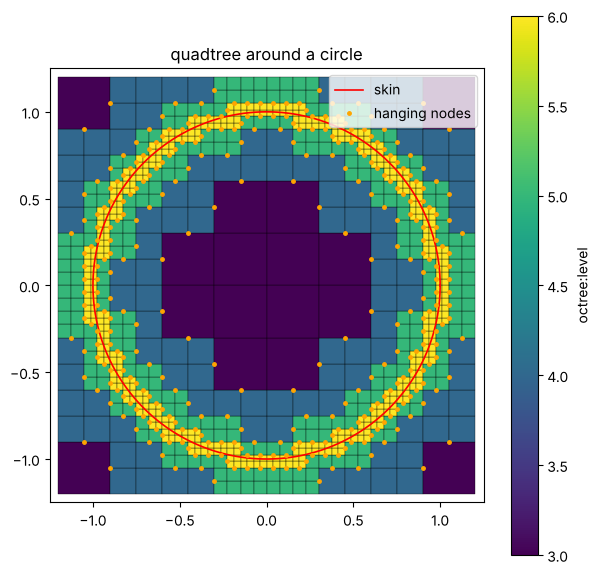

In [2]:
quad, rep = mp.octree(circle(), max_level=6, bounds=[-1.2, -1.2, 0, 1.2, 1.2, 0], return_report=True)
print(rep)

lo, hi = leaf_boxes(quad)
level = np.asarray(quad.cell_data['octree:level'][0])
cut = np.asarray(quad.cell_data['octree:cut'][0])
hanging = np.asarray(quad.point_data['octree:hanging']).astype(bool)

verts = [[(a[0], a[1]), (b[0], a[1]), (b[0], b[1]), (a[0], b[1])] for a, b in zip(lo, hi)]
fig, ax = plt.subplots(figsize=(7, 7))
pc = PolyCollection(verts, array=level, cmap='viridis', edgecolors='k', linewidths=0.25)
ax.add_collection(pc)
t = np.linspace(0, 2 * np.pi, 400)
ax.plot(np.cos(t), np.sin(t), 'r-', lw=1.2, label='skin')
pts = np.asarray(quad.points)
ax.plot(pts[hanging, 0], pts[hanging, 1], 'o', ms=2.5, color='orange', label='hanging nodes')
ax.set_xlim(-1.25, 1.25); ax.set_ylim(-1.25, 1.25); ax.set_aspect('equal')
fig.colorbar(pc, ax=ax, label='octree:level'); ax.legend(loc='upper right')
ax.set_title('quadtree around a circle')
save_fig('octree_quadtree')
plt.show()


## The interior converges to the area

`fill='inside'` keeps the leaves whose centre is inside the polyline (winding number). The kept area approaches pi as `max_level` grows.

In [3]:
for max_level in (3, 4, 5, 6, 7):
    tree, r = mp.octree(circle(), max_level=max_level, bounds=[-1.2, -1.2, 0, 1.2, 1.2, 0],
                        fill='inside', return_report=True)
    edge = r['root_size'] / 2.0 ** np.asarray(tree.cell_data['octree:level'][0])
    area = float(np.sum(edge ** 2))
    print(f'max_level {max_level}: {r["num_leaves"]:5d} leaves, area {area:.4f}, error {abs(area - np.pi) / np.pi:.2%}')


max_level 3:    20 leaves, area 2.8800, error 8.33%
max_level 4:    68 leaves, area 3.1500, error 0.27%
max_level 5:   172 leaves, area 3.1275, error 0.45%
max_level 6:   420 leaves, area 3.1556, error 0.45%
max_level 7:   832 leaves, area 3.1359, error 0.18%


## An octree around a sphere

A triangle surface gives the 3-D octree. The finest leaves exist only in the shell the surface cuts; the volume of the `inside` leaves converges to 4/3 pi.

In [4]:
sphere = uv_sphere()
box = [-1.2, -1.2, -1.2, 1.2, 1.2, 1.2]
shell, rep = mp.octree(sphere, max_level=4, bounds=box, return_report=True)
level = np.asarray(shell.cell_data['octree:level'][0])
cut = np.asarray(shell.cell_data['octree:cut'][0])
print(rep)
print('leaves per level:', dict(zip(*np.unique(level, return_counts=True))))
print('every cut leaf is at the finest level:', bool(np.all(level[cut == 1] == 4)))

for max_level in (3, 4, 5):
    tree, r = mp.octree(sphere, max_level=max_level, bounds=box, fill='inside', return_report=True)
    edge = r['root_size'] / 2.0 ** np.asarray(tree.cell_data['octree:level'][0])
    vol = float(np.sum(edge ** 3))
    print(f'max_level {max_level}: {r["num_leaves"]:6d} leaves, volume {vol:.4f}, error {abs(vol - 4 / 3 * np.pi) / (4 / 3 * np.pi):.2%}')


{'dimension': 3, 'origin': [-1.2, -1.2, -1.2], 'root_size': 2.4, 'num_leaves': 2080, 'num_hanging': 1128, 'finest_level': 4}
leaves per level: {np.int64(3): np.int64(288), np.int64(4): np.int64(1792)}
every cut leaf is at the finest level: True
max_level 3:    160 leaves, volume 4.3200, error 3.13%
max_level 4:    648 leaves, volume 4.0770, error 2.67%
max_level 5:   3648 leaves, volume 4.1850, error 0.09%


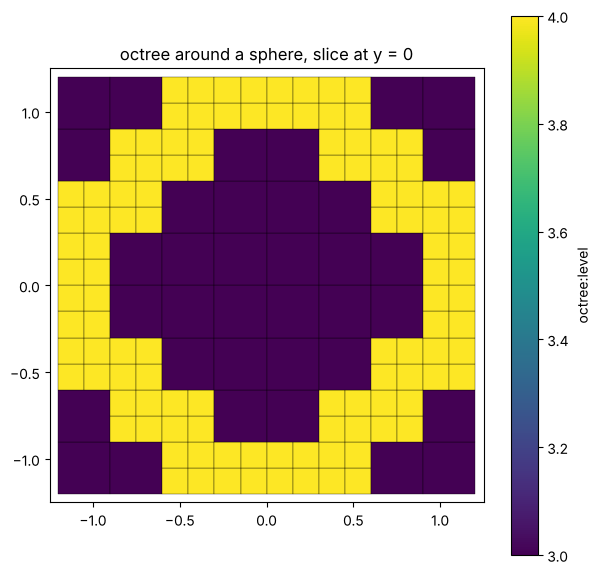

In [5]:
# Render the mid-plane of the tree with PyVista when GL is available, and fall
# back to a matplotlib slice of the leaves otherwise.
def to_pyvista(mesh):
    with tempfile.NamedTemporaryFile(suffix='.vtu', delete=False) as f:
        tmp = f.name
    try:
        mp.write(tmp, mesh)
        return pv.read(tmp)
    finally:
        os.unlink(tmp)


def gl_available():
    """Probe off-screen GL in a child process: a missing GL stack can kill the
    interpreter outright, which no try/except in this one would survive."""
    if pv is None:
        return False
    import subprocess, sys
    probe = ('import pyvista as pv; pv.OFF_SCREEN = True; pl = pv.Plotter(off_screen=True); '
             'pl.add_mesh(pv.Sphere()); pl.screenshot(return_img=True)')
    try:
        return subprocess.run([sys.executable, '-c', probe], capture_output=True,
                              timeout=120).returncode == 0
    except Exception:
        return False


rendered = False
if gl_available():
    try:
        grid = to_pyvista(shell)
        half = grid.clip(normal='y', origin=(0, 0, 0))
        pl = pv.Plotter(off_screen=True, window_size=(900, 700))
        pl.add_mesh(half, scalars='octree:level', cmap='viridis', show_edges=True,
                    edge_color='#333333', line_width=0.3)
        pl.camera_position = 'iso'
        img = pl.screenshot(return_img=True)
        pl.close()
        plt.figure(figsize=(8, 6)); plt.imshow(img); plt.axis('off')
        plt.title('octree around a sphere, cut open')
        save_fig('octree_sphere')
        plt.show()
        rendered = True
    except Exception as exc:  # pragma: no cover - head-less GL fallback
        print('PyVista render skipped:', exc)

if not rendered:
    lo, hi = leaf_boxes(shell)
    sel = (lo[:, 1] <= 0.0) & (hi[:, 1] > 0.0)
    verts = [[(a[0], a[2]), (b[0], a[2]), (b[0], b[2]), (a[0], b[2])] for a, b in zip(lo[sel], hi[sel])]
    fig, ax = plt.subplots(figsize=(7, 7))
    pc = PolyCollection(verts, array=level[sel], cmap='viridis', edgecolors='k', linewidths=0.25)
    ax.add_collection(pc)
    ax.set_xlim(-1.25, 1.25); ax.set_ylim(-1.25, 1.25); ax.set_aspect('equal')
    fig.colorbar(pc, ax=ax, label='octree:level')
    ax.set_title('octree around a sphere, slice at y = 0')
    save_fig('octree_sphere')
    plt.show()


## A uniform tree is the voxel grid

With `min_level == max_level` nothing is adaptive and the lattice is `voxelize`'s, point for point.

In [6]:
b = [-1, -1, -1, 1, 1, 1]
uniform = mp.octree(sphere, min_level=3, max_level=3, bounds=b)
vox = mp.voxelize(sphere, resolution=(8, 8, 8), bounds=b)
print('same points:', np.asarray(uniform.points).tobytes() == np.asarray(vox.points).tobytes())
print('leaves:', len(uniform.cells[0].data), '- voxels:', len(vox.cells[0].data))


same points: True
leaves: 512 - voxels: 512


## 2-D voxelize

The same planar skin gives uniform pixels with a two-entry resolution; `fill='inside'` uses the winding number of the polyline and refuses one that does not close.

In [7]:
pixels, rep = mp.voxelize(circle(), resolution=(48, 48), padding=0.1, fill='inside', return_report=True)
cell_area = rep['spacing'][0] * rep['spacing'][1]
print(pixels.cells[0].type, rep['num_occupied'], 'pixels, area', round(rep['num_occupied'] * cell_area, 4))


quad 1500 pixels, area 3.151
